# Two MLPs for a binary target (0/1)
Model A: small MLP (like the example notebook). Model B: bigger MLP with dropout.
Both: ReLU hidden layers, sigmoid output, binary cross-entropy, mini-batch training with early stopping.

In [232]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.callbacks import EarlyStopping, ModelCheckpoint

from preprocessing import prepare_data

In [233]:
'''
# funcao da magui prepare_data

def _doy365(date):
    """Dia do ano com 366 -> 365 (ano bissexto), como no cos de YDOY."""
    return np.minimum(date.dt.dayofyear.to_numpy(), 365)


def _learn_fills(train_val, strategy, doy_half_window):
    """Aprende, SÓ em train_val, as medianas usadas na imputação."""
    fill_cols = ["CHL_log", "CHL_uncertainty"]
    obs = train_val.dropna(subset=fill_cols)
    fills = {"global": obs[fill_cols].median()}
    if strategy == "season_median":
        fills["season"] = obs.groupby("Season")[fill_cols].median()
    if strategy == "doy_window_median":
        fills["obs_doy"] = _doy365(obs["Date"])
        fills["obs_vals"] = obs[fill_cols].to_numpy()
        fills["half_window"] = doy_half_window
    return fills


def _apply_fills(d, strategy, fills):
    """Preenche CHL_log e CHL_uncertainty em falta (imputação em log(CHL))."""
    d = d.copy()
    fill_cols = ["CHL_log", "CHL_uncertainty"]
    miss = d[fill_cols].isna().any(axis=1).to_numpy()
    if not miss.any():
        return d

    if strategy == "global_median":
        for c in fill_cols:
            d[c] = d[c].fillna(fills["global"][c])

    elif strategy == "season_median":
        for c in fill_cols:
            by_season = d["Season"].map(fills["season"][c])
            d[c] = d[c].fillna(by_season).fillna(fills["global"][c])

    elif strategy == "doy_window_median":
        doy = _doy365(d["Date"])
        for i in np.flatnonzero(miss):
            diff = np.abs(fills["obs_doy"] - doy[i])
            diff = np.minimum(diff, 365 - diff)           # distância circular
            in_win = diff <= fills["half_window"]
            for j, c in enumerate(fill_cols):
                if np.isnan(d[c].iloc[i]):
                    v = (np.median(fills["obs_vals"][in_win, j])
                         if in_win.any() else fills["global"][c])
                    d.iloc[i, d.columns.get_loc(c)] = v
    return d

def prepare_data(strategy, split_test, one_hot_cluster=True, sin_doy=True, test_frac=0.15, doy_half_window=15,
                 seed=42):
    """Prepara os dados do Task 1.

    Parâmetros
    ----------
    strategy : str, estratégia para os missing values (CHL, CHL_uncertainty)
        "drop_rows"         – remove linhas de train/val com missing
        "drop_features"     – remove CHL_log e CHL_uncertainty
        "global_median"     – mediana global (CHL em log)
        "season_median"     – mediana por estação do ano
        "doy_window_median" – mediana numa janela de ±doy_half_window dias
    split_test : str, forma de separar o conjunto de test
        "recent"     – 15% mais recentes, sem linhas com missing
        "stratified" – 15% do total, só linhas completas, espalhadas no tempo
                       e por estações, preservando a mistura de classes
    one_hot_cluster : bool – spatial_cluster -> 6 colunas 0/1
    sin_doy : bool – acrescenta sin(2π·DOY/365)

    Devolve
    -------
    (X_train_val, y_train_val, X_test, y_test)
    """

    # Read data
    df = pd.read_excel("classification_task1_train.xlsx")
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values(["Date", "spatial_cluster"], kind="stable").reset_index(drop=True)


    # Separar os dados de test dos restantes dados
    if split_test == "recent":
        n_test = int(round(test_frac * len(df)))
        cutoff = df["Date"].iloc[len(df) - n_test]
        is_test = (df["Date"] >= cutoff).to_numpy()
        complete = df[["CHL", "CHL_uncertainty"]].notna().all(axis=1).to_numpy()
        test_mask = is_test & complete      # linhas completas do test
        rest_mask = ~is_test    

    else:
        rng = np.random.default_rng(seed)
        d = df.assign(_complete=df[["CHL", "CHL_uncertainty"]].notna().all(axis=1))

        by_date = d.groupby("Date").agg(n_rows=("HAB", "size"),
                                        all_complete=("_complete", "all"),
                                        hab=("HAB", "max"),
                                        season=("Season", "first"))
        elig = by_date[by_date["all_complete"]]

        n_target_dates = int(round(test_frac * len(df) / elig["n_rows"].mean()))
        n_target_dates = min(n_target_dates, len(elig))

        chosen = []
        for _, g in elig.groupby(["season", "hab"]):
            k = int(round(n_target_dates * len(g) / len(elig)))
            k = min(max(k, 1), len(g))                                        # >=1 data por estrato
            pos = ((rng.uniform() + np.arange(k)) * len(g) / k).astype(int)   # posições espaçadas
            chosen.extend(g.index[pos])

        test_mask = df["Date"].isin(chosen).to_numpy()    
        rest_mask = ~test_mask

    train_val, test = df[rest_mask].copy(), df[test_mask].copy()



    # log(CHL), sin_doy, one-hot do cluster
    # (aplicadas igualmente a train_val e test, para as colunas coincidirem) 
    # pode-se fazer isto porque não aprende nada
    train_val = train_val.copy()
    test = test.copy()
    train_val["CHL_log"] = np.log(train_val["CHL"]) 
    test["CHL_log"] = np.log(test["CHL"])                    
    if sin_doy:
        train_val["sin_doy"] = np.sin(2 * np.pi * _doy365(train_val["Date"]) / 365)
        test["sin_doy"] = np.sin(2 * np.pi * _doy365(test["Date"]) / 365)
    if one_hot_cluster:
        for c in range(6):                       
            train_val[f"cluster_{c}"] = (train_val["spatial_cluster"] == c).astype(int)
            test[f"cluster_{c}"] = (test["spatial_cluster"] == c).astype(int)


    # Estratégia para missing values (só para train_val, porque o test já é completo)
    if strategy == "drop_rows":
        train_val = train_val.dropna(subset=["CHL_log", "CHL_uncertainty"])
    elif strategy != "drop_features":
        fills = _learn_fills(train_val, strategy, doy_half_window)
        train_val = _apply_fills(train_val, strategy, fills)

    # Colunas finais (as restantes são redundantes e são descartadas)
    cols = ["Season", "SST", "UI", "YDOY"]
    if sin_doy:
        cols.append("sin_doy")
    if strategy != "drop_features":
        cols += ["CHL_log", "CHL_uncertainty"]
    cols += ([f"cluster_{c}" for c in range(6)]
             if one_hot_cluster else ["spatial_cluster"])

    assert not test[cols].drop(columns="Season").isna().any().any(), "test com NaN"
    assert not train_val[cols].isna().any().any(), "train_val com NaN"

    return (train_val[cols], train_val["HAB"],
            test[cols], test["HAB"])
'''

'\n# funcao da magui prepare_data\n\ndef _doy365(date):\n    """Dia do ano com 366 -> 365 (ano bissexto), como no cos de YDOY."""\n    return np.minimum(date.dt.dayofyear.to_numpy(), 365)\n\n\ndef _learn_fills(train_val, strategy, doy_half_window):\n    """Aprende, SÓ em train_val, as medianas usadas na imputação."""\n    fill_cols = ["CHL_log", "CHL_uncertainty"]\n    obs = train_val.dropna(subset=fill_cols)\n    fills = {"global": obs[fill_cols].median()}\n    if strategy == "season_median":\n        fills["season"] = obs.groupby("Season")[fill_cols].median()\n    if strategy == "doy_window_median":\n        fills["obs_doy"] = _doy365(obs["Date"])\n        fills["obs_vals"] = obs[fill_cols].to_numpy()\n        fills["half_window"] = doy_half_window\n    return fills\n\n\ndef _apply_fills(d, strategy, fills):\n    """Preenche CHL_log e CHL_uncertainty em falta (imputação em log(CHL))."""\n    d = d.copy()\n    fill_cols = ["CHL_log", "CHL_uncertainty"]\n    miss = d[fill_cols].isna().

In [234]:
batch_size = 50
lr = 0.0003

In [235]:
X_train_val, y_train_val, X_test, y_test = prepare_data(strategy="doy_window_median", split_test="stratified", one_hot_cluster=True, sin_doy=True)

In [236]:
X_train_val.describe
X_test.describe

<bound method DataFrame.describe of       season_Winter  season_Spring  season_Summer  season_Fall    SST  \
14                0              1              0            0  13.25   
22                0              1              0            0  12.73   
29                0              1              0            0  12.90   
30                0              1              0            0  13.43   
32                0              1              0            0  13.46   
...             ...            ...            ...          ...    ...   
1022              0              0              0            1  13.56   
1023              0              0              0            1  13.23   
1036              0              0              0            1  13.54   
1037              0              0              0            1  14.63   
1062              1              0              0            0  13.40   

            UI      YDOY   sin_doy   CHL_log  CHL_uncertainty  cluster_0  \
14   -0.455

In [237]:
#check
print(len(X_train_val))        # number of rows
print(X_train_val.shape[0])   # also number of rows


# Check which Continuous columns to scale (skip 0/1 columns)
num_cols = [X_train_val.columns.get_loc(c)
            for c in X_train_val.select_dtypes(include="number").columns
            if X_train_val[c].nunique() > 2]

X_train_val = X_train_val.to_numpy(dtype="float32")
X_test      = X_test.to_numpy(dtype="float32")

# Binary target: plain 0/1 vector (no one-hot needed)
y_train_val = np.asarray(y_train_val).ravel().astype("float32")
y_test      = np.asarray(y_test).ravel().astype("float32")

n_features = X_train_val.shape[1]
print("features:", n_features)
print("share of 1s -> train_val: %.3f | test: %.3f" % (y_train_val.mean(), y_test.mean()))


903
903
features: 16
share of 1s -> train_val: 0.123 | test: 0.169


In [238]:
# Validation split from train_val (test stays untouched)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15, random_state=42, stratify=y_train_val)

# Scaling: fit on TRAIN only, continuous columns only
scaler = StandardScaler().fit(X_train[:, num_cols])
for A in (X_train, X_val, X_test):
    A[:, num_cols] = scaler.transform(A[:, num_cols])

# If classes are very imbalanced, set class_weight = {0: 1.0, 1: w} (e.g. w = n0/n1)
'''
n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
class_wei = {0: 1.0, 1: n0 / n1}
'''

class_wei = None


In [248]:
# Baseline to beat: always predicting the majority class
base = max(y_val.mean(), 1 - y_val.mean())
print("Majority-class accuracy on validation: %.3f" % base)

Majority-class accuracy on validation: 0.875


In [240]:
from ast import If


def build_mlp(units, dropout=0.0, name="mlp", Regul=True, Reg=1e-4, seed=42):
    keras.utils.set_random_seed(seed)          # same initial weights every time
    m = Sequential(name=name)
    m.add(Input(shape=(n_features,)))
    for u in units:
        if Regul:
            m.add(Dense(u, activation="relu", kernel_regularizer=keras.regularizers.l2(Reg)))
        else:
            m.add(Dense(u, activation="relu"))
        if dropout > 0:
            m.add(Dropout(dropout))
    m.add(Dense(1, activation="sigmoid"))          # binary output
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m


def train(model, name, n_epochs, pat):
    cbs = [EarlyStopping(monitor="val_auc", mode="max", patience=pat,
              start_from_epoch=20, restore_best_weights=True),
           ModelCheckpoint(f"best_{name}.keras", monitor="val_auc", mode="max", save_best_only=True)]
    return model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size,
                     validation_data=(X_val, y_val), callbacks=cbs,
                     class_weight=class_wei, verbose=1)


In [241]:
# Model A: small (like the example notebook)
model_A = build_mlp([16, 8], dropout=0.2, name="A_small", Regul=True, Reg=1e-3)
# Model B: bigger + dropout
model_B = build_mlp([64, 32], dropout=0.4, name="B_big_dropout", Regul=True, Reg=1e-3)

model_A.summary(); model_B.summary()

Model: "A_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_84 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_52 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_85 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_53 (Dropout)            │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 417 (1.63 KB)

 Trainable params: 417 (1.63 KB)

 Non-trainable params: 0 (0.00 B)

Model: "B_big_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_87 (Dense)                │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_54 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_88 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_55 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_89 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

In [242]:
hist_A = train(model_A, "A_small", 300, pat=20)         # exactly 26 epochs

Epoch 1/300
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.6493 - auc: 0.5878 - loss: 0.6608 - val_accuracy: 0.6691 - val_auc: 0.4748 - val_loss: 0.6793
Epoch 2/300
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6936 - auc: 0.6313 - loss: 0.6353 - val_accuracy: 0.7500 - val_auc: 0.4859 - val_loss: 0.6567
Epoch 3/300
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7366 - auc: 0.5829 - loss: 0.6237 - val_accuracy: 0.7794 - val_auc: 0.4899 - val_loss: 0.6343
Epoch 4/300
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7536 - auc: 0.6161 - loss: 0.6050 - val_accuracy: 0.8235 - val_auc: 0.4980 - val_loss: 0.6131
Epoch 5/300
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7862 - auc: 0.6269 - loss: 0.5705 - val_accuracy: 0.8456 - val_auc: 0.5012 - val_loss: 0.5925
Epoch 6/300
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8136 - auc: 0.6625 - loss: 0.5535 - val_accuracy: 0.8529 - val_auc: 0.5035 - val_loss: 0.5727
Epoch 7/300
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 1

In [243]:
hist_B = train(model_B, "B_big_dropout", 400, pat=30)   # exactly 80 epochs

Epoch 1/400
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.5919 - auc: 0.5300 - loss: 0.7413 - val_accuracy: 0.8088 - val_auc: 0.5326 - val_loss: 0.7009
Epoch 2/400
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7158 - auc: 0.5116 - loss: 0.6887 - val_accuracy: 0.8824 - val_auc: 0.5257 - val_loss: 0.6526
Epoch 3/400
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8018 - auc: 0.5688 - loss: 0.6324 - val_accuracy: 0.8750 - val_auc: 0.5447 - val_loss: 0.6089
Epoch 4/400
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8149 - auc: 0.4892 - loss: 0.6051 - val_accuracy: 0.8750 - val_auc: 0.5769 - val_loss: 0.5694
Epoch 5/400
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8462 - auc: 0.5337 - loss: 0.5669 - val_accuracy: 0.8750 - val_auc: 0.6199 - val_loss: 0.5350
Epoch 6/400
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8540 - auc: 0.5705 - loss: 0.5302 - val_accuracy: 0.8750 - val_auc: 0.6572 - val_loss: 0.5046
Epoch 7/400
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11

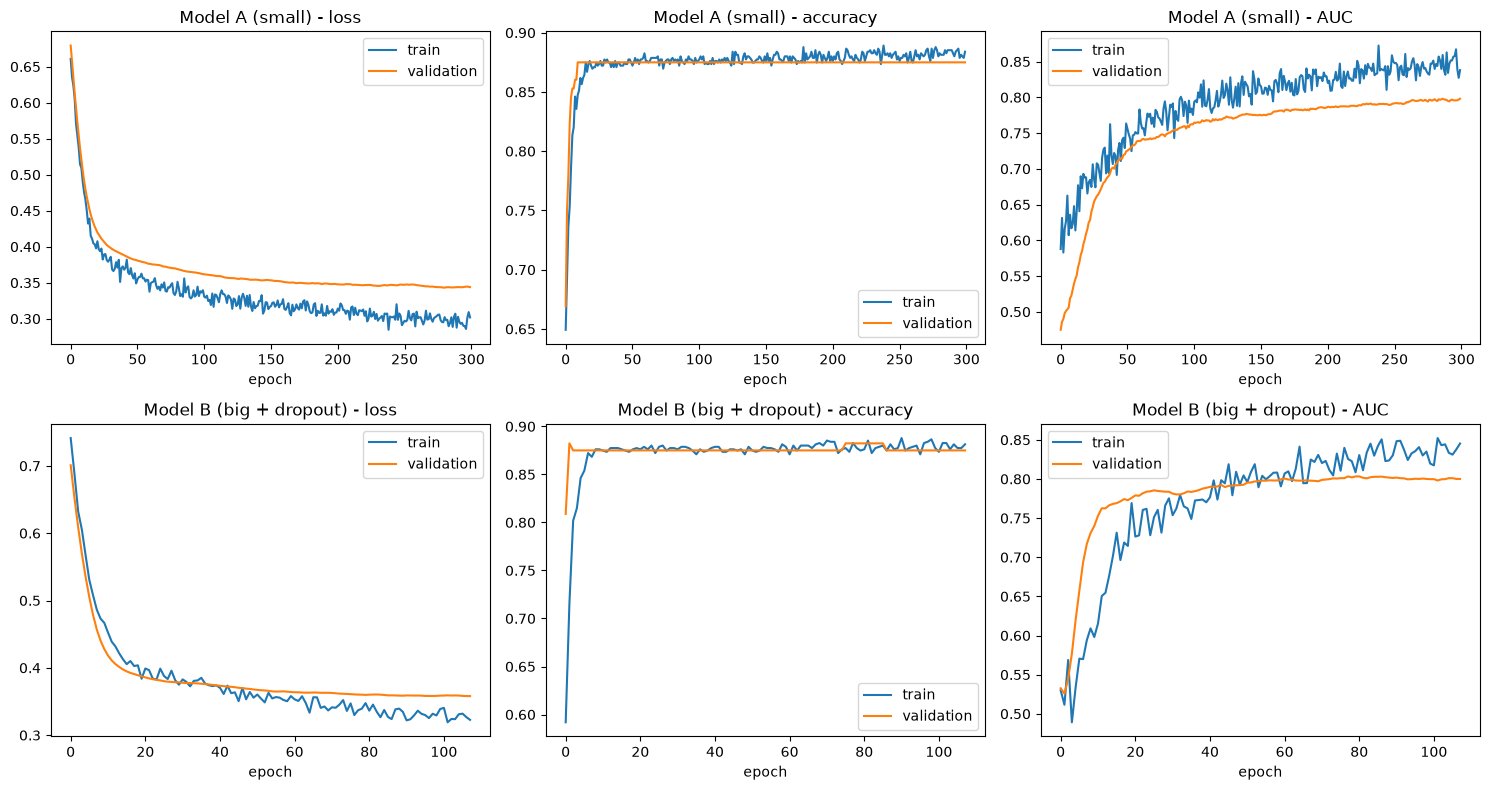

In [244]:
# Training curves: loss, accuracy and AUC (train vs validation)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for row, (h, title) in enumerate([(hist_A, "Model A (small)"), (hist_B, "Model B (big + dropout)")]):
    for col, (metric, label) in enumerate([("loss", "loss"), ("accuracy", "accuracy"), ("auc", "AUC")]):
        ax[row, col].plot(h.history[metric], label="train")
        ax[row, col].plot(h.history["val_" + metric], label="validation")
        ax[row, col].set_title(f"{title} - {label}")
        ax[row, col].set_xlabel("epoch")
        ax[row, col].legend()
plt.tight_layout(); plt.show()

In [245]:
'''
def evaluate(model, X, y, label):
    p = model.predict(X, verbose=0).ravel()
    pred = (p >= 0.5).astype(int)
    acc = (pred == y).mean()
    auc = roc_auc_score(y, p)
    print(f"{label}: accuracy={acc:.4f} | AUC={auc:.4f}")
    return pred, acc, auc

models = [("A_small", model_A, hist_A), ("B_big_dropout", model_B, hist_B)]

print("=== AUC on train and validation (use validation to choose the model) ===")
for name, m, h in models:
    evaluate(m, X_train, y_train, f"{name} TRAIN     ")
    evaluate(m, X_val,   y_val,   f"{name} VALIDATION")
    best_ep = int(np.argmax(h.history["val_auc"]))
    print(f"{name}: best val AUC in training = {max(h.history['val_auc']):.4f} (epoch {best_ep + 1}) "
          f"| last epoch val AUC = {h.history['val_auc'][-1]:.4f}\n")

print("=== TEST (look only after choosing the model) ===")
for name, m, h in models:
    pred, _, _ = evaluate(m, X_test, y_test, f"{name} TEST")
    print(classification_report(y_test, pred, digits=3))
    print("Confusion matrix (rows = true 0/1, cols = predicted 0/1):")
    print(confusion_matrix(y_test, pred)); print()
    '''


'\ndef evaluate(model, X, y, label):\n    p = model.predict(X, verbose=0).ravel()\n    pred = (p >= 0.5).astype(int)\n    acc = (pred == y).mean()\n    auc = roc_auc_score(y, p)\n    print(f"{label}: accuracy={acc:.4f} | AUC={auc:.4f}")\n    return pred, acc, auc\n\nmodels = [("A_small", model_A, hist_A), ("B_big_dropout", model_B, hist_B)]\n\nprint("=== AUC on train and validation (use validation to choose the model) ===")\nfor name, m, h in models:\n    evaluate(m, X_train, y_train, f"{name} TRAIN     ")\n    evaluate(m, X_val,   y_val,   f"{name} VALIDATION")\n    best_ep = int(np.argmax(h.history["val_auc"]))\n    print(f"{name}: best val AUC in training = {max(h.history[\'val_auc\']):.4f} (epoch {best_ep + 1}) "\n          f"| last epoch val AUC = {h.history[\'val_auc\'][-1]:.4f}\n")\n\nprint("=== TEST (look only after choosing the model) ===")\nfor name, m, h in models:\n    pred, _, _ = evaluate(m, X_test, y_test, f"{name} TEST")\n    print(classification_report(y_test, pred, di

In [246]:
'''
from sklearn.metrics import (accuracy_score, roc_auc_score,
                             precision_score, recall_score, f1_score,
                             precision_recall_curve)

def best_threshold(model):
    # Threshold that maximizes F1 on VALIDATION (never on test)
    p = model.predict(X_val, verbose=0).ravel()
    prec, rec, thr = precision_recall_curve(y_val, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.argmax(f1[:-1])])

def summary(model, name, threshold=0.5):
    print(f"===== {name} (threshold = {threshold:.3f}) =====")
    for label, X, y in [("train", X_train, y_train),
                        ("validation", X_val, y_val),
                        ("test", X_test, y_test)]:
        p = model.predict(X, verbose=0).ravel()
        pred = (p >= threshold).astype(int)
        print(f"{label:<11} accuracy = {accuracy_score(y, pred):.4f} | AUC = {roc_auc_score(y, p):.4f}")

    p = model.predict(X_test, verbose=0).ravel()
    pred = (p >= threshold).astype(int)
    print("\nTest set (class 1 = positive):")
    print(f"  accuracy  = {accuracy_score(y_test, pred):.4f}")
    print(f"  precision = {precision_score(y_test, pred, zero_division=0):.4f}")
    print(f"  recall    = {recall_score(y_test, pred, zero_division=0):.4f}")
    print(f"  f1-score  = {f1_score(y_test, pred, zero_division=0):.4f}\n")

# Fixed threshold:
summary(model_A, "A_small", threshold=0.5)
summary(model_B, "B_big_dropout", threshold=0.5)

# Or threshold chosen on validation:
# summary(model_A, "A_small", threshold=best_threshold(model_A))
# summary(model_B, "B_big_dropout", threshold=best_threshold(model_B))
'''

'\nfrom sklearn.metrics import (accuracy_score, roc_auc_score,\n                             precision_score, recall_score, f1_score,\n                             precision_recall_curve)\n\ndef best_threshold(model):\n    # Threshold that maximizes F1 on VALIDATION (never on test)\n    p = model.predict(X_val, verbose=0).ravel()\n    prec, rec, thr = precision_recall_curve(y_val, p)\n    f1 = 2 * prec * rec / (prec + rec + 1e-12)\n    return float(thr[np.argmax(f1[:-1])])\n\ndef summary(model, name, threshold=0.5):\n    print(f"===== {name} (threshold = {threshold:.3f}) =====")\n    for label, X, y in [("train", X_train, y_train),\n                        ("validation", X_val, y_val),\n                        ("test", X_test, y_test)]:\n        p = model.predict(X, verbose=0).ravel()\n        pred = (p >= threshold).astype(int)\n        print(f"{label:<11} accuracy = {accuracy_score(y, pred):.4f} | AUC = {roc_auc_score(y, p):.4f}")\n\n    p = model.predict(X_test, verbose=0).ravel()\n

In [247]:
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             precision_recall_curve)

THRESHOLD = None   # None = choose automatically on validation (max F1); or set a number, e.g. 0.25

def report(model, name):
    ytr, yva, yte = y_train.astype(int), y_val.astype(int), y_test.astype(int)
    p_tr = model.predict(X_train, verbose=0).ravel()
    p_va = model.predict(X_val,   verbose=0).ravel()
    p_te = model.predict(X_test,  verbose=0).ravel()

    if THRESHOLD is None:
        prec, rec, thr = precision_recall_curve(yva, p_va)
        f1 = 2 * prec * rec / (prec + rec + 1e-12)
        t = float(thr[np.argmax(f1[:-1])])
    else:
        t = THRESHOLD

    pred = lambda p: (p >= t).astype(int)

    print(f"===== {name} =====")
    print(f"Train       accuracy = {accuracy_score(ytr, pred(p_tr)):.4f} | AUC = {roc_auc_score(ytr, p_tr):.4f}")
    print(f"Validation  accuracy = {accuracy_score(yva, pred(p_va)):.4f} | AUC = {roc_auc_score(yva, p_va):.4f}")
    print(f"Test        accuracy = {accuracy_score(yte, pred(p_te)):.4f} | AUC = {roc_auc_score(yte, p_te):.4f}")

    print(f"\nThreshold used: {t:.3f}")

    yp = pred(p_te)
    print(f"\n* accuracy on test : {accuracy_score(yte, yp):.4f}")
    print(f"* precision on test: {precision_score(yte, yp, zero_division=0):.4f}")
    print(f"* recall on test   : {recall_score(yte, yp, zero_division=0):.4f}")
    print(f"* f1-score on test : {f1_score(yte, yp, zero_division=0):.4f}")

    print("\nConfusion matrix (rows = true 0/1, cols = predicted 0/1):")
    print(confusion_matrix(yte, yp))
    print()

report(model_A, "A_small")
report(model_B, "B_big_dropout")

===== A_small =====
Train       accuracy = 0.8227 | AUC = 0.8703
Validation  accuracy = 0.7941 | AUC = 0.7914
Test        accuracy = 0.7312 | AUC = 0.7833

Threshold used: 0.212

* accuracy on test : 0.7312
* precision on test: 0.3333
* recall on test   : 0.5926
* f1-score on test : 0.4267

Confusion matrix (rows = true 0/1, cols = predicted 0/1):
[[101  32]
 [ 11  16]]

===== B_big_dropout =====
Train       accuracy = 0.8018 | AUC = 0.8569
Validation  accuracy = 0.7941 | AUC = 0.8013
Test        accuracy = 0.7188 | AUC = 0.8020

Threshold used: 0.186

* accuracy on test : 0.7188
* precision on test: 0.3333
* recall on test   : 0.6667
* f1-score on test : 0.4444

Confusion matrix (rows = true 0/1, cols = predicted 0/1):
[[97 36]
 [ 9 18]]

